In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy
from scipy import linalg
import seaborn as sns
from matplotlib import pyplot as plt
import fastplotlib as fpl
import tifffile
import random
import imageio.v3 as iio
from skophys.datasets import ARProcess, ARProcessMovie

%matplotlib inline

fastplotlib version from git (0.4.0) and __version__ (0.5.0) don't match.
wgpu version from git (0.15.3) and __version__ (0.22.1) don't match.
rendercanvas version from git (2.0.0) and __version__ (2.0.1) don't match.


Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

Valid,Device,Type,Backend,Driver
✅,AMD Radeon 780M (RADV GFX1103_R1),IntegratedGPU,Vulkan,Mesa 24.2.8
✅ (default),NVIDIA RTX A1000 6GB Laptop GPU,DiscreteGPU,Vulkan,550.142
✅,NVIDIA RTX A1000 6GB Laptop GPU,DiscreteGPU,Vulkan,550.142
❗ limited,"llvmpipe (LLVM 19.1.0, 256 bits)",CPU,Vulkan,Mesa 24.2.8 (LLVM 19.1.0)
❌,"AMD Radeon 780M (radeonsi, gfx1103_r1, LLVM 19.1.0, DRM 3.59, 6.12.4-200.fc41.x86_64)",Unknown,OpenGL,4.6 (Core Profile) Mesa 24.2.8


pygfx version from git (0.6.0) and __version__ (0.9.0) don't match.
Incompatible version of wgpu:
    Detected 0.15.3.post134+g6b77f99, need >=(0, 19, 0), <(0, 23, 0).
    To update, use e.g. `pip install -U wgpu`.
Incompatible version of pylinalg:
    Detected 0.6.3, need >=(0, 6, 7), <(0, 7, 0).
    To update, use e.g. `pip install -U pylinalg`.


In [2]:
fpl.select_adapter(fpl.enumerate_adapters()[0])

In [464]:
locs = np.array([
    [0, 0],
    [5, 0]
])

In [666]:
ar_model = ARProcessMovie(
    n_timepoints=5_000,
    n_components=2,
    ar_noise_sigma=0.1,
    obs_noise_sigma=0.1,
    movie_dims=(10, 15),
    component_locs=locs,
    decay_constant = 0.6,
    baselines=[1, 1],
)

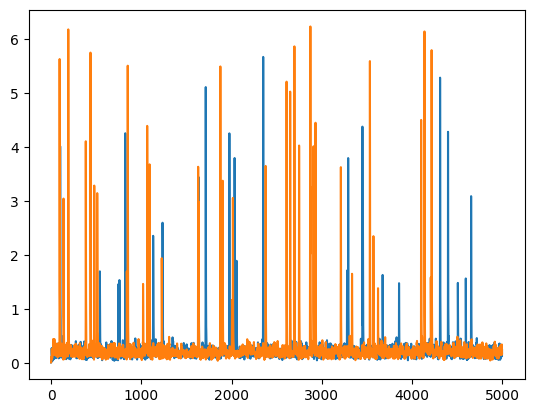

In [667]:
plt.plot(ar_model.traces.T)

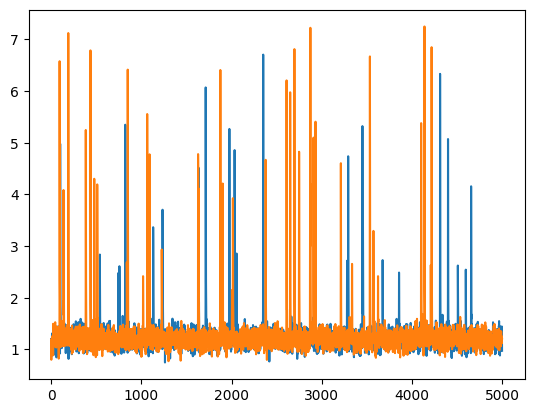

In [668]:
plt.plot(ar_model.traces_obs.T)

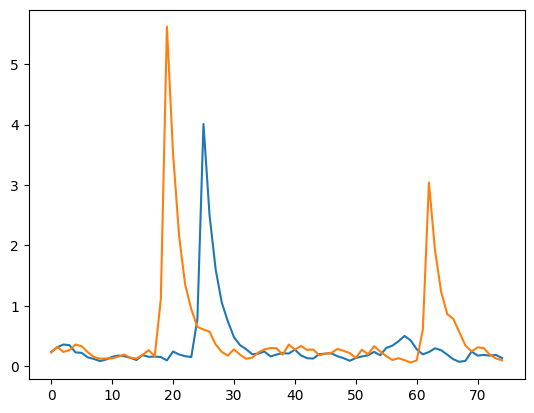

In [669]:
plt.plot(ar_model.traces.T[75:150])

In [670]:
movie = ar_model.movie[:1000]
movie_full = ar_model.movie

# Shuffle in time and see if CCA breaks down

PCA should work if shuffled and non-overlapping

nn Sim matching will not work if overlapping, nn CCA will work

# Look at cov, compare with non PF, try less wide traces

## Can converge faster with larger decay constant, need to run 1,000 times and see what happens. How fast converge, and how many of those have real filters.

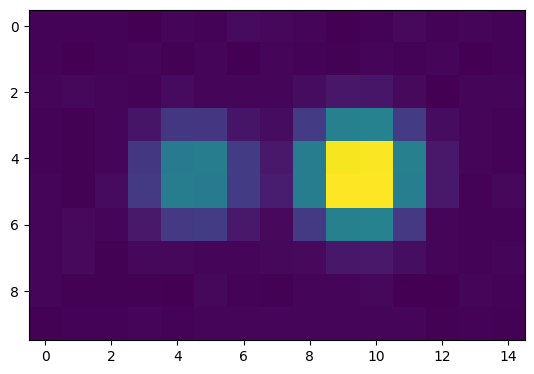

In [671]:
plt.imshow(movie.std(axis=0))

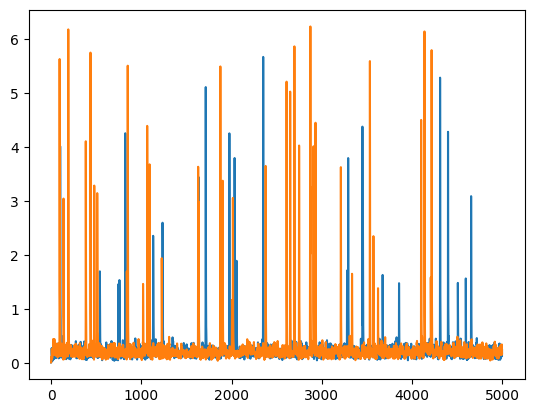

In [672]:
plt.plot(ar_model.traces[:1000].T)

RFBOutputContext()

JupyterRenderCanvas(css_height='300.0px', css_width='500.0px')
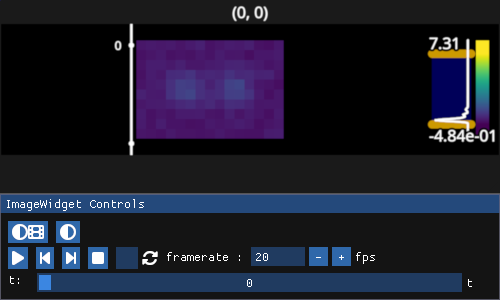

In [673]:
iw = fpl.ImageWidget(movie, cmap="viridis")
iw.show()

RFBOutputContext()

JupyterRenderCanvas(css_height='300.0px', css_width='500.0px')
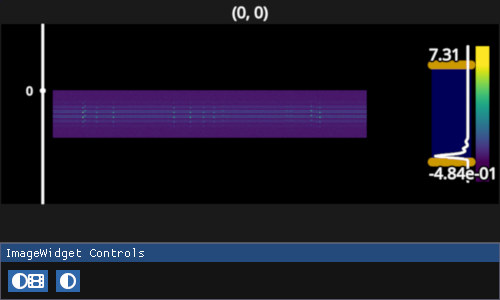

In [674]:
fpl.ImageWidget(movie.reshape(movie.shape[0], np.prod(movie.shape[1:])).T, cmap="viridis").show()

RFBOutputContext()

JupyterRenderCanvas(css_height='300.0px', css_width='500.0px')
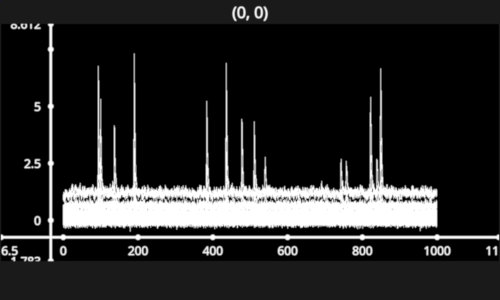

In [675]:
fig = fpl.Figure()

fig[0, 0].add_line_collection(movie.reshape(movie.shape[0], np.prod(movie.shape[1:])).T, thickness=1.0)

fig.show(maintain_aspect=False)

In [676]:
from skophys.preprocessing import Vectorizer, UnVectorizer

In [677]:
X = Vectorizer().transform(movie)
unvec = UnVectorizer(movie.shape[1:])

X_full = Vectorizer().transform(movie_full)

In [685]:
X.shape

(150, 1000)

# Random shuffle pixels

In [688]:
ixs = np.arange(X.shape[1])
np.random.shuffle(ixs)

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/features/_base.py:18: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


JupyterRenderCanvas(css_height='300.0px', css_width='500.0px')
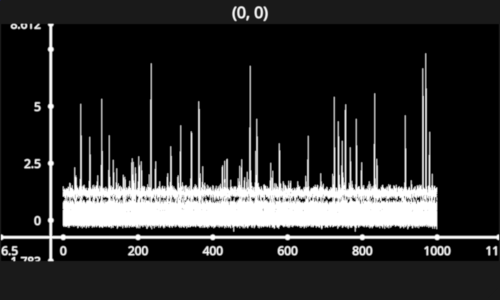

In [690]:
X = X[:, ixs]

fig = fpl.Figure()

fig[0, 0].add_line_collection(X, thickness=1.0)

fig.show(maintain_aspect=False)

In [691]:
lag = 1
lag_step = 1
n_pixels = X.shape[0]

Hs = list()

for i in range(n_pixels):
    Hs.append(scipy.linalg.hankel(X[i, :lag * lag_step * 2], X[i, (lag * lag_step * 2) - 1:])[::lag_step])

H = np.zeros((lag * 2 * n_pixels, X.shape[1] - (lag * lag_step * 2) + 1))
for i, H_i in enumerate(Hs):
    H[i::n_pixels] = H_i


Hs = list()

for i in range(n_pixels):
    Hs.append(scipy.linalg.hankel(X_full[i, :lag * lag_step * 2], X_full[i, (lag * lag_step * 2) - 1:])[::lag_step])

H_full = np.zeros((lag * 2 * n_pixels, X_full.shape[1] - (lag * lag_step * 2) + 1))
for i, H_i in enumerate(Hs):
    H_full[i::n_pixels] = H_i

In [692]:
H.shape, H_full.shape

((300, 999), (300, 4999))

In [693]:
mu0 = H[:lag * n_pixels].mean(axis=1)
mu1 = H[lag * n_pixels:].mean(axis=1)

H[:lag * n_pixels] -= mu0[:, None]
H[lag * n_pixels:] -= mu1[:, None]

past = H[:lag * n_pixels]
future = H[lag * n_pixels:]

mu0 = H_full[:lag * n_pixels].mean(axis=1)
mu1 = H_full[lag * n_pixels:].mean(axis=1)

H_full[:lag * n_pixels] -= mu0[:, None]
H_full[lag * n_pixels:] -= mu1[:, None]

past_full = H_full[:lag * n_pixels]
future_full = H_full[lag * n_pixels:]

<Axes: >

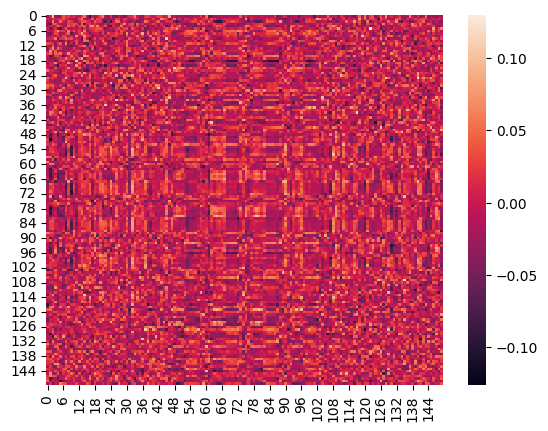

In [694]:
sns.heatmap(cosine_similarity(past, future))

# k: number of components

In [695]:
k = 2

# list of slices of lags, each slice is the indices in `W` that represent pixels for one lag time

In [696]:
lag_slices = [slice(n_pixels * i, (i + 1) * n_pixels) for i in range(lag * 2)]
lag_slices

[slice(0, 150, None), slice(150, 300, None)]

In [697]:
H_nw = np.vstack(
    [
        past,
        future,
    ]
)

H = np.vstack(
    [
        scipy.linalg.pinv(scipy.linalg.sqrtm(past @ past.T / past.shape[1])) @ past,
        scipy.linalg.pinv(scipy.linalg.sqrtm(future @ future.T / future.shape[1])) @ future,
    ]
)

H_full = np.vstack(
    [
        scipy.linalg.pinv(scipy.linalg.sqrtm(past_full @ past_full.T / past_full.shape[1])) @ past_full,
        scipy.linalg.pinv(scipy.linalg.sqrtm(future_full @ future_full.T / future_full.shape[1])) @ future_full,
    ]
)

In [698]:
H.shape

(300, 999)

In [699]:
X_init = H

In [700]:
cov = X_init.T @ X_init

XTX = cov / np.linalg.norm(cov, ord="fro")

T = XTX.shape[0]

In [701]:
eta = 0.1

In [702]:
from tqdm.notebook import tqdm

In [703]:
movie.shape

(1000, 10, 15)

In [704]:
# Ys = list()

Y = (np.random.randn(k, T) / np.sqrt(T))

# Y /= Y.max()
# Y *= X.max()

for iteration in tqdm(range(150_000)):
    # Ys.append(Y)
    Y_old = Y
    Y = Y + eta * Y @ (XTX - Y.T @ Y)

    zeroed = Y.sum(axis=1) == 0.0
    Y[zeroed] = (np.random.randn(zeroed.sum(), T) / np.sqrt(T)).clip(0)
    
    Y = Y.clip(0)

    er = np.divide(np.abs(Y - Y_old), np.abs(Y_old + 1e-2)).max() / eta

    if er < 1e-3:
        break

  0%|          | 0/150000 [00:00<?, ?it/s]

In [705]:
er

np.float64(0.000999697263164949)

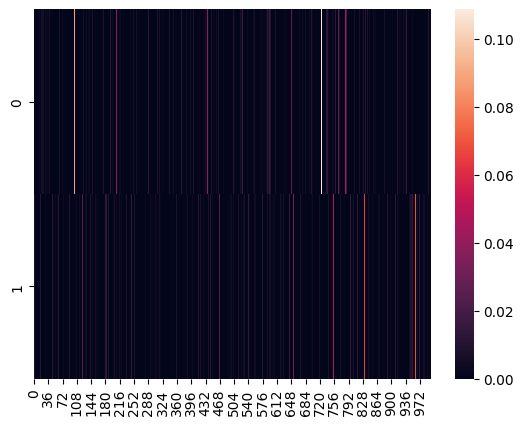

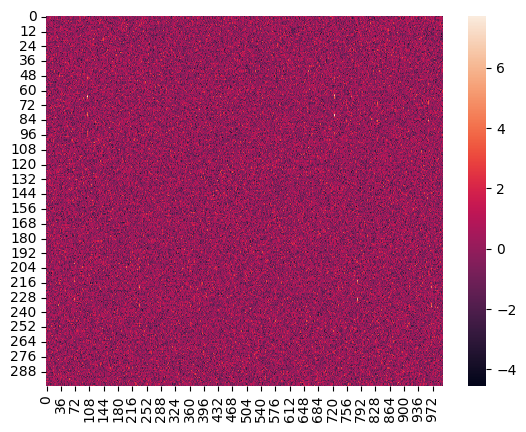

In [706]:
sns.heatmap(Y)
plt.show()

sns.heatmap(X_init)
plt.show()

In [707]:
W = Y @ X_init.T #/ sum_y_squared
W_nw = Y @ H_nw.T #/ sum_y_squared
M = Y @ Y.T #/ sum_y_squared

In [708]:
W.shape

(2, 300)

In [709]:
Y.shape

(2, 999)

<Axes: >

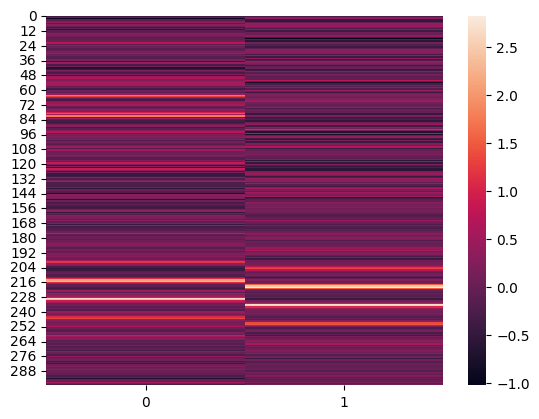

In [710]:
sns.heatmap(W.T)

<Axes: >

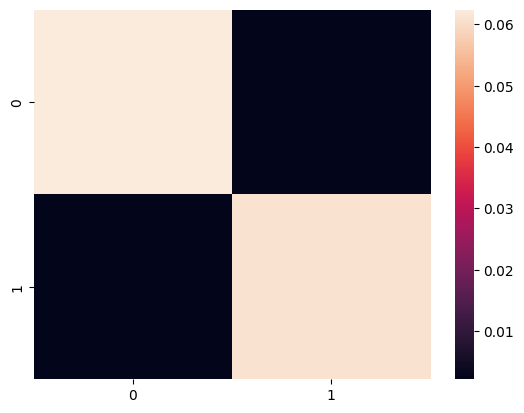

In [711]:
sns.heatmap(M)

In [712]:
M

array([[0.06241591, 0.0021376 ],
       [0.0021376 , 0.06093294]])

In [713]:
np.linalg.eigvals(M)

array([0.06393697, 0.05941187])

In [714]:
from itertools import product

In [715]:
from ipywidgets import HBox

In [716]:
l_i = 0

In [717]:
# make images by reshaing each lag within `W`
images, titles = list(), list(),
for k_i, l_i in product(range(k), range(lag)):
    images.append(unvec.transform(W[k_i, lag_slices[l_i]].T))
    titles.append(f"k_{k_i}, l_{l_i}")

iw_W = fpl.ImageWidget(
    images,
    cmap="viridis",
    names=titles,
    figure_shape=(k, lag),
    figure_kwargs={"size": (800, 1000)},
)

images_nw = list()
for k_i, l_i in product(range(k), range(lag)):
    images_nw.append(unvec.transform(W_nw[k_i, lag_slices[l_i]].T))

iw_W_nw = fpl.ImageWidget(
    images_nw,
    cmap="viridis",
    names=titles,
    figure_shape=(k, lag),
    figure_kwargs={"size": (800, 1000)},
)

iw_ground = fpl.ImageWidget(
    [img for img in ar_model.spatial],
    cmap="viridis",
    figure_shape=(k, lag),
    figure_kwargs={"size": (800, 1000)},
)

HBox([iw_W.show(), iw_W_nw.show(), iw_ground.show()])

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/features/_base.py:18: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


RFBOutputContext()

RFBOutputContext()

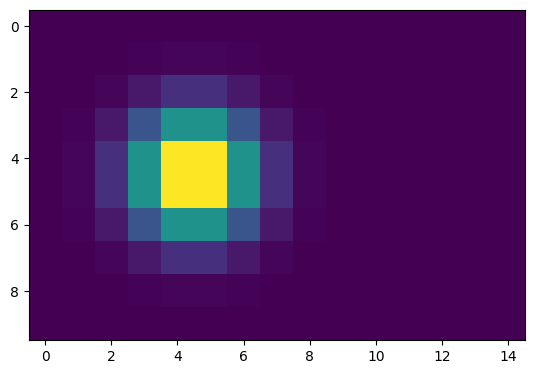

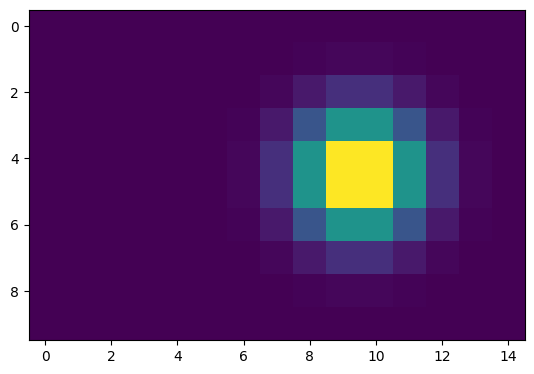

In [718]:
for i in ar_model.spatial:
    plt.imshow(i)
    plt.show()

plt.show()

Text(0.5, 1.0, 'Y, offline init')

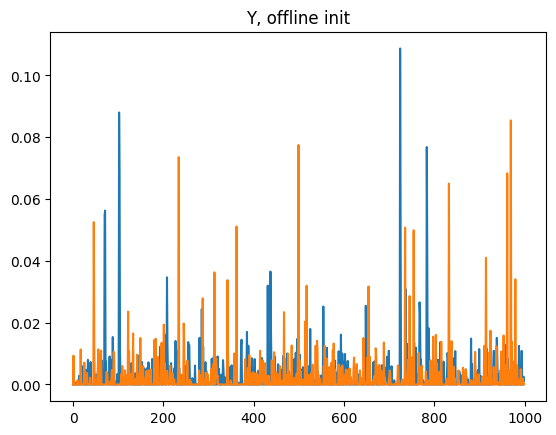

In [719]:
plt.plot(Y.T)
plt.title("Y, offline init")

In [720]:
X_train = ar_model.traces[:, 1:Y.shape[1] + 1]

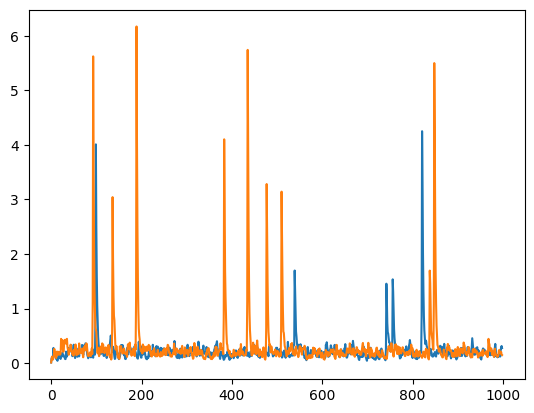

In [721]:
plt.plot(X_train.T)

In [621]:
Y.T.shape

(999, 2)

In [622]:
ar_model.traces.shape

(2, 5000)

In [623]:
from sklearn.metrics.pairwise import cosine_similarity

<Axes: >

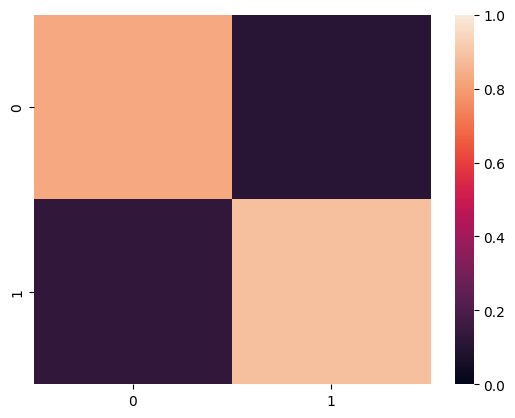

In [628]:
sns.heatmap(cosine_similarity(X_train, Y), vmin=0, vmax=1)

In [517]:
def spatial_to_rgba(spatial_filters: np.ndarray, percentile: float = 90.0, colors: list = None):
    """
    Get an RGBA array that represents the given spatial filters

    Parameters
    ----------
    spatial_filters: np.ndarray
        shape: [n_components, n_rows, n_cols]

    percentile: float, default 90.0
        only pixels above this percentile are considered

    Returns
    -------
    [n_components, n_rows, n_cols, 4], last dim is rgba

    """
    
    out = np.zeros((*spatial_filters.shape, 4))
    
    if colors is None:
        colors = np.random.rand(spatial_filters.shape[0], 3)

    for i, a in enumerate(spatial_filters):
        rgba_component = np.zeros((*a.shape, 4))
        # threshold using percentile
        rows, cols = np.where(a > np.percentile(a, percentile))

        # set a random color
        rgba_component[rows, cols, :-1] = colors[i]

        # set alpha value as the filter value
        rgba_component[rows, cols, -1] = a[rows, cols]

        out[i] = rgba_component

    return out

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..2.0].


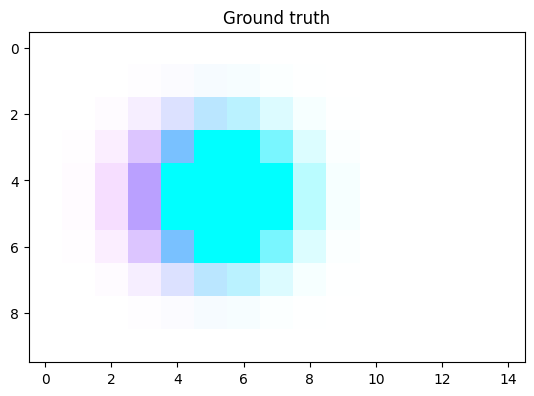

In [312]:
rgba = spatial_to_rgba(ar_model.spatial, colors=[(1, 0, 1), (0, 1, 1)], percentile=50)

for img in rgba:
    plt.imshow(img)

plt.title("Ground truth")
plt.show()

# W = Y @ X_w

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.8904117396328086].


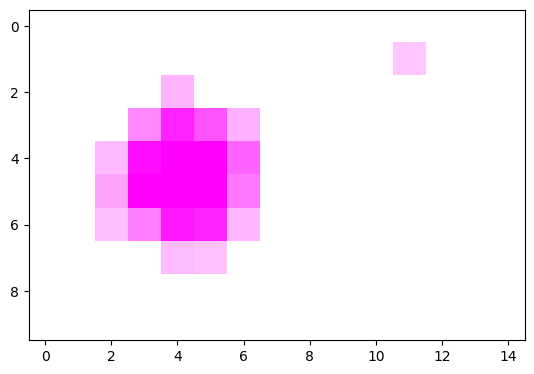

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..9.021495069369095].


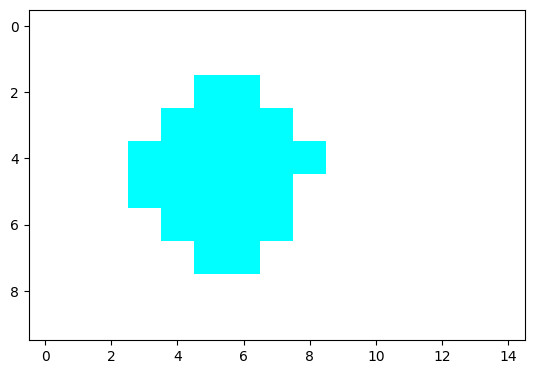

In [313]:
rgba = spatial_to_rgba(unvec.transform(W_nw[:, lag_slices[l_i]].T), colors=[(1, 0, 1), (0, 1, 1)], percentile=85)

for img in rgba:
    plt.imshow(img)
    plt.show()

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.8904117396328086].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..9.021495069369095].


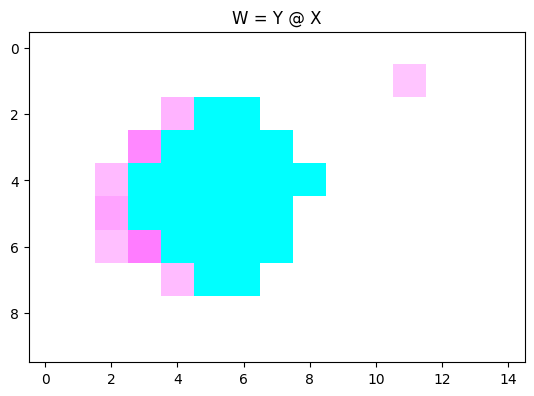

In [314]:
rgba = spatial_to_rgba(unvec.transform(W_nw[:, lag_slices[l_i]].T), colors=[(1, 0, 1), (0, 1, 1)], percentile=85)

for img in rgba:
    plt.imshow(img)

plt.title("W = Y @ X")
plt.show()

In [61]:
sum_y_squared = np.square(Y).sum(axis=1)[:, None]
sum_y_squared.shape

(2, 1)

In [62]:
W = Y @ X_init.T #/ sum_y_squared
M = Y @ Y.T #/ sum_y_squared

In [63]:
W.shape

(2, 300)

In [64]:
Y.shape

(2, 999)

In [65]:
def update_weight(W, M, x_t, y_t, y_hat):
    """ Update weight matrix of W and M.
    Equation (8) in the original paper.
    """
    y_dim = y_t.shape[0]
    y_hat += (y_t * y_t)
    
    # (3,1) x (1,2) = (3,2)
    dW = y_t[:,np.newaxis].dot( x_t[np.newaxis,:] - (W.T.dot(y_t[:,np.newaxis])).T)
    #dW = dW / y_hat[:,np.newaxis]
    # (3, 2)
    
    for i in range(y_dim):
        if y_hat[i] > 0:
            W[i] += (dW[i] / y_hat[i])
    
    # (3,1) x (1,3) = (3,3)
    dM = y_t[:,np.newaxis].dot( y_t[np.newaxis,:] - (M.T.dot(y_t[:,np.newaxis])).T)
    #dM = dM / y_hat[:,np.newaxis]
    
    # Set diagonal elements to zero
    for i in range(M.shape[0]):
        dM[i,i] = 0.0
    
    for i in range(y_dim):
        if y_hat[i] > 0:
            M[i] += (dM[i] / y_hat[i])

In [66]:
def adjust_y_i(y_t, x_t, y_index, lambd=0.5):
    """ If the node in y_t is not active previously, adjust it.
    Equation (5) in the original paper.
    """
    # y_t = (3,)
    # x_t = (2,)
    
    y_dim = y_t.shape[0]
    
    # Calculate squree L2 norm of x_t
    x_norm_sq = x_t.dot(x_t)    
    y_t_sqs = y_t * y_t # (3,)
    
    y_t_adj = np.empty_like(y_t)
    
    d_i = x_norm_sq - (np.sum(y_t_sqs) - y_t_sqs[y_index])
    d_i_sq = d_i * d_i
    if d_i_sq <= lambd:
        return 0.0
    else:
        if d_i < 0.0:
            print("d_i was negative: {}".format(d_i))
            d_i = 0.0
    return np.sqrt(d_i)

In [67]:
W_init = W.copy()
M_init = M.copy()

In [68]:
from qpsolvers import solve_qp

In [69]:
def solve_yt(x_t, Wt, Mt, k):
    return solve_qp(
        (Mt + Mt.T) / 2,
        -Wt @ x_t,
        lb=np.zeros(k),
        solver="cvxopt"
    )

In [70]:
x_dim = H_full.shape[0]
T = H_full.shape[1]

y_dim = k

# Active set {i}
active_i_s = []
active_counts = np.zeros([y_dim], dtype=np.int32)

# Iteration count for convergence
max_iteration = 100

y_t_sum = np.zeros([y_dim])
y_hat = np.zeros([y_dim]) # 3

clusters = []

for t in tqdm(range(T)):
    # Get one input sample x_t
    x_t = H_full[:, t].copy() # (2,)
    
    # Zero initialze y_t
    # y_t = np.zeros(y_dim)
    y_t = solve_yt(x_t, W, M, k=k)
    # for i in range(k):
    #     # If 'i' is in the active set {i}
    #     for it in range(max_iteration):
    #         y_t_previous = y_t.copy()
    #         y_t_i = (W[i]  @ x_t) - (M[i] @ y_t_previous)
            
    #         y_t[i] = max(y_t_i, 0)
            
    #         if y_t[i] - y_t_previous[i] < 1e-5:
    #             break
    
    # for i in range(y_dim):
    #     if active_counts[i] == 0:
    #         y_t[i] = adjust_y_i(y_t, x_t, i)
                
    # for i in range(y_dim):
    #     if y_t[i] != 0.0:
    #         active_counts[i] += 1
            
    # for i in range(y_dim):
    #     if (i not in active_i_s) and active_counts[i] > 0:
    #         active_i_s.append(i)

    # update_weight(W, M, x_t, y_t, y_hat)
    
    clusters.append(y_t)
    
Y = np.vstack(clusters)

  0%|          | 0/4999 [00:00<?, ?it/s]

<Axes: >

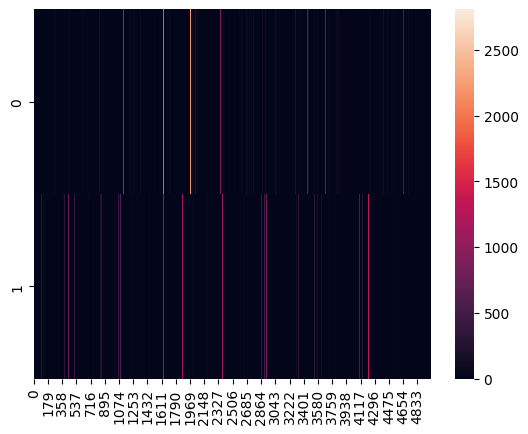

In [71]:
sns.heatmap(Y.T)

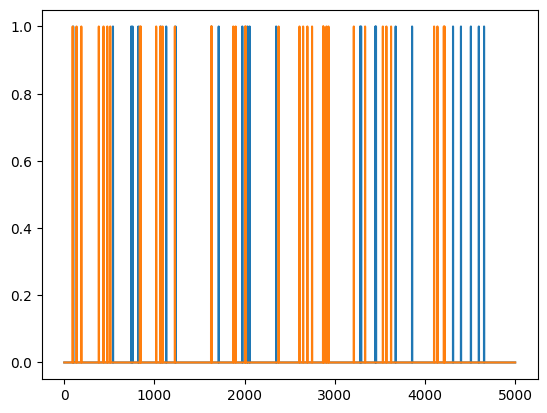

In [72]:
plt.plot(ar_model.spikes.T)

Text(0.5, 1.0, 'Y, online')

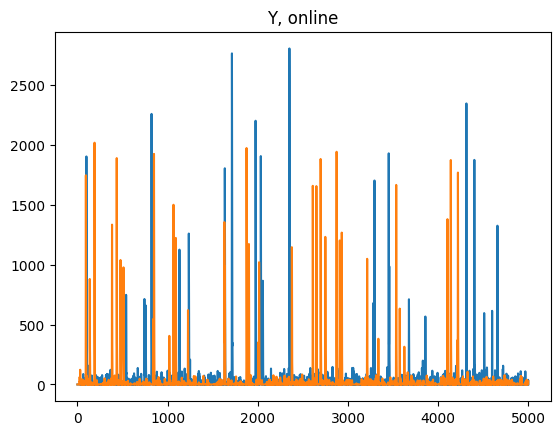

In [73]:
plt.plot(Y)
plt.title("Y, online")

Text(0.5, 1.0, 'ground_truth')

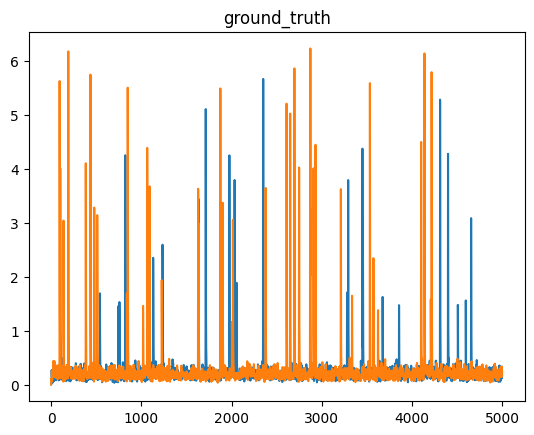

In [74]:
plt.plot(ar_model.traces.T)
plt.title("ground_truth")

In [75]:
traces_mc.T.max(axis=0)

NameError: name 'traces_mc' is not defined

Text(0.5, 1.0, 'Y - ground truth')

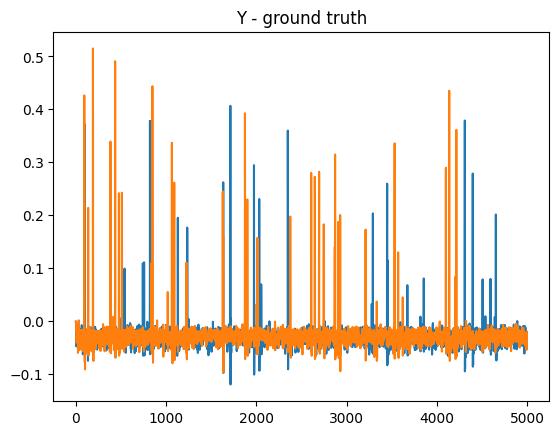

In [78]:
# traces_mc = (ar_model.traces - ar_model.traces.mean())[:, 1:]
traces_mc = ar_model.traces[:, :-1]

plt.plot((Y / Y.max(axis=0)) - (traces_mc.T / traces_mc.T.max(axis=0)))
plt.title("Y - ground truth")

In [73]:
Y.shape

(1997, 4)

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/features/_base.py:18: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


JupyterRenderCanvas(css_height='500.0px', css_width='900.0px')
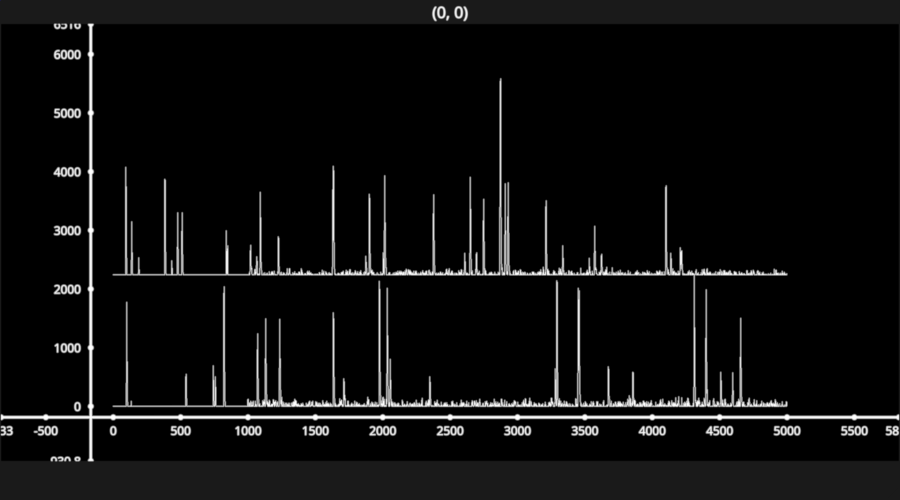

In [208]:
fig = fpl.Figure(size=(900, 500))

fig[0, 0].add_line_stack(Y.T, thickness=1, separation=0.1)

fig.show(maintain_aspect=False)